<a href="https://colab.research.google.com/github/praveenkumarmaka33-star/DSA0302/blob/main/ASSIGNMENT_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import nltk
from nltk import PCFG
from nltk.grammar import FeatureGrammar
from nltk.parse import RecursiveDescentParser, EarleyChartParser, ViterbiParser
import matplotlib.pyplot as plt
import time
import pandas as pd

print("NLTK and plotting libraries imported successfully.")

NLTK and plotting libraries imported successfully.


In [ ]:
# Define the Grammar with Feature Structures for Agreement & Subcategorization
grammar_spec = """
% start S

# --- Grammar Rules ---
S -> NP[NUM=?n, PER=?p] VP[NUM=?n, PER=?p]
S -> Aux[NUM=?n, PER=?p] NP[NUM=?n, PER=?p] VP[NUM=?n, PER=?p, +INV]
S -> VP[+IMP]

# Phrase structure rules
NP[NUM=?n, PER=?p] -> Det[NUM=?n] N[NUM=?n, PER=?p]
NP[NUM=pl] -> N[NUM=pl]
NP[NUM=?n, PER=?p] -> Pron[NUM=?n, PER=?p, CASE=nom]
NP[NUM=?n] -> NP[NUM=?n] PP

VP[NUM=?n, PER=?p, INV=?i] -> V[SUBCAT=intr, NUM=?n, PER=?p]
VP[NUM=?n, PER=?p, INV=?i] -> V[SUBCAT=trans, NUM=?n, PER=?p] NP
VP[NUM=?n, PER=?p, INV=?i] -> V[SUBCAT=ditrans, NUM=?n, PER=?p] NP NP
VP[NUM=?n, PER=?p, INV=?i] -> V[SUBCAT=comp, NUM=?n, PER=?p] Sbar
VP[NUM=?n, PER=?p, INV=?i] -> V[SUBCAT=pp_comp, NUM=?n, PER=?p] PP

Sbar -> Comp S
PP -> P NP

# --- Lexicon ---
# Determiners
Det[NUM=sg] -> 'the' | 'a' | 'this'
Det[NUM=pl] -> 'the' | 'these' | 'many'

# Nouns
N[NUM=sg, PER=3] -> 'student' | 'hostel' | 'fee' | 'library' | 'seminar' | 'room' | 'timetable' | 'exam' | 'placement'
N[NUM=pl, PER=3] -> 'students' | 'hostels' | 'fees' | 'libraries' | 'seminars' | 'rooms' | 'timetables' | 'exams' | 'placements'

# Pronouns
Pron[NUM=sg, PER=1, CASE=nom] -> 'I'
Pron[NUM=sg, PER=2, CASE=nom] -> 'you'
Pron[NUM=pl, PER=1, CASE=nom] -> 'we'
Pron[NUM=sg, PER=3, CASE=nom] -> 'he' | 'she'

# Verbs with Subcategorization, Number and Person
V[SUBCAT=intr, NUM=sg, PER=3, -INV] -> 'crashes' | 'exists'
V[SUBCAT=intr, NUM=pl, -INV] -> 'crash' | 'exist'
V[SUBCAT=trans, NUM=sg, PER=3, -INV] -> 'submits' | 'checks' | 'books'
V[SUBCAT=trans, NUM=pl, -INV] -> 'submit' | 'check' | 'book'
V[SUBCAT=trans, NUM=sg, PER=2, -INV] -> 'submit' | 'check' | 'book'
V[SUBCAT=ditrans, NUM=sg, PER=3, -INV] -> 'sends' | 'gives'
V[SUBCAT=ditrans, NUM=pl, -INV] -> 'send' | 'give'
V[SUBCAT=ditrans, NUM=sg, PER=2, -INV] -> 'send' | 'give'

V[SUBCAT=comp, NUM=sg, PER=3, -INV] -> 'claims' | 'says'
V[SUBCAT=comp, NUM=pl, -INV] -> 'claim' | 'say'

V[SUBCAT=pp_comp, NUM=sg, PER=3, -INV] -> 'applies' | 'caters'
V[SUBCAT=pp_comp, NUM=pl, -INV] -> 'apply' | 'cater'
V[SUBCAT=pp_comp, NUM=sg, PER=2, -INV] -> 'apply' | 'cater'

# Auxiliaries
Aux[NUM=sg, PER=3] -> 'does' | 'is'
Aux[NUM=pl] -> 'do' | 'are'
Aux[NUM=sg, PER=2] -> 'do' | 'are'

# Prepositions
P -> 'with' | 'for' | 'near' | 'at' | 'about' | 'in'

# Complementizer
Comp -> 'that'
"""

feature_grammar = FeatureGrammar.fromstring(grammar_spec)
print("Feature-based Context-Free Grammar parsed successfully.")

Feature-based Context-Free Grammar parsed successfully.


In [ ]:
# Define the Probabilistic Context-Free Grammar (PCFG)
pcfg_spec = """
S -> NP VP [1.0]

# NP rules
NP -> Det N [0.5]
NP -> N [0.2]
NP -> Pron [0.1]
NP -> NP PP [0.2]

# VP rules
VP -> V_intr [0.2]
VP -> V_trans NP [0.4]
VP -> V_ditrans NP NP [0.1]
VP -> V_comp Sbar [0.1]
VP -> V_pp_comp PP [0.2]

Sbar -> Comp S [1.0]
PP -> P NP [1.0]

# Terminals
Det -> 'the' [0.6] | 'a' [0.3] | 'this' [0.1]
N -> 'student' [0.1] | 'students' [0.1] | 'hostel' [0.1] | 'fee' [0.1] | 'fees' [0.1] | 'library' [0.1] | 'room' [0.1] | 'timetable' [0.1] | 'exam' [0.1] | 'placement' [0.1]
Pron -> 'I' [0.5] | 'you' [0.5]

V_intr -> 'crashes' [0.5] | 'exist' [0.5]
V_trans -> 'submits' [0.3] | 'submit' [0.3] | 'checks' [0.2] | 'book' [0.2]
V_ditrans -> 'sends' [0.5] | 'send' [0.5]
V_comp -> 'claims' [0.5] | 'say' [0.5]
V_pp_comp -> 'applies' [0.5] | 'apply' [0.5]

P -> 'with' [0.3] | 'for' [0.3] | 'near' [0.2] | 'at' [0.2]
Comp -> 'that' [1.0]
"""

pcfg_grammar = PCFG.fromstring(pcfg_spec)
print("PCFG initialized successfully.")

PCFG initialized successfully.


In [ ]:
# 30-Sentence Query Set (Grammatical, Ungrammatical, and Ambiguous)
queries = [
    ("the student submits the fee", "Grammatical"),
    ("students check the timetables", "Grammatical"),
    ("I book the room", "Grammatical"),
    ("you apply for a hostel", "Grammatical"),
    ("the students submit the fees near the library", "Ambiguous PP"),
    ("book the room near the library for the seminar", "Ambiguous PP"),
    ("the student submits", "Ungrammatical (Under-complemented)"),
    ("the student crashes the fee", "Ungrammatical (Over-complemented)"),
    ("these student submit the fee", "Ungrammatical (Agreement Error)"),
    ("the student submit the fee", "Ungrammatical (Agreement Error)"),
    ("we send the student the fee", "Grammatical"),
    ("the exam crashes", "Grammatical"),
    ("this library exists", "Grammatical"),
    ("I say that the student submits the fee", "Grammatical"),
    ("the student claims that exams exist", "Grammatical"),
    ("these students book rooms", "Grammatical"),
    ("you send the students the room for the seminar", "Ambiguous PP"),
    ("the placements exist at the library", "Grammatical"),
    ("a student checks a placement", "Grammatical"),
    ("he books the room", "Grammatical"),
    ("she checks the fees", "Grammatical"),
    ("the hostiles exist", "Grammatical"),
    ("the student applies for the exam", "Grammatical"),
    ("these libraries book the room", "Grammatical"),
    ("the student with the fee", "Ungrammatical (No VP)"),
    ("submits the fee", "Grammatical (Imperative-like VP)"),
    ("I send you the student", "Grammatical"),
    ("you book this room near the library", "Ambiguous PP"),
    ("the students claim that the hostel crashes", "Grammatical"),
    ("the student with the fee near the library", "Ungrammatical (No VP)")
]

print(f"Total test cases loaded: {len(queries)}")

Total test cases loaded: 30


In [ ]:
# Instantiating NLTK Parsers
td_parser = RecursiveDescentParser(feature_grammar)
earley_parser = EarleyChartParser(feature_grammar)
pcfg_viterbi_parser = ViterbiParser(pcfg_grammar)

# Benchmark and Evaluation Routine
results = []

for sentence_str, label in queries:
    tokens = sentence_str.split()
    n_words = len(tokens)

    # Measure Earley Parsing Time & Chart States
    start_time = time.time()
    try:
        earley_trees = list(earley_parser.parse(tokens))
        num_parses = len(earley_trees)
    except Exception as e:
        earley_trees = []
        num_parses = 0
    elapsed_time = (time.time() - start_time) * 1000  # ms

    # Measure PCFG Viterbi Parse
    pcfg_success = False
    try:
        # Map tokens to match terminal categories in standard PCFG where needed
        pcfg_tokens = []
        for t in tokens:
            if t in ['submits', 'submit', 'checks', 'book']: pcfg_tokens.append(t)
            elif t in ['crashes', 'exist']: pcfg_tokens.append(t)
            elif t in ['sends', 'send']: pcfg_tokens.append(t)
            elif t in ['claims', 'say']: pcfg_tokens.append(t)
            elif t in ['applies', 'apply']: pcfg_tokens.append(t)
            else: pcfg_tokens.append(t)
        viterbi_trees = list(pcfg_viterbi_parser.parse(pcfg_tokens))
        pcfg_success = len(viterbi_trees) > 0
    except:
        pcfg_success = False

    results.append({
        "Sentence": sentence_str,
        "Length": n_words,
        "Type": label,
        "Parsed": num_parses > 0,
        "Parses Found": num_parses,
        "Time (ms)": round(elapsed_time, 3),
        "PCFG Decoded": pcfg_success
    })

df_results = pd.DataFrame(results)
display(df_results)

,Sentence,Length,Type,Parsed,Parses Found,Time (ms),PCFG Decoded
0,the student submits the fee,5,Grammatical,False,0,2.048,True
1,students check the timetables,4,Grammatical,False,0,1.180,False
2,I book the room,4,Grammatical,False,0,0.714,True
3,you apply for a hostel,5,Grammatical,False,0,0.809,True
4,the students submit the fees near the library,8,Ambiguous PP,False,0,0.941,True
5,book the room near the library for the seminar,9,Ambiguous PP,False,0,1.480,False
6,the student submits,3,Ungrammatical (Under-complemented),False,0,0.780,False
7,the student crashes the fee,5,Ungrammatical (Over-complemented),False,0,0.733,False
8,these student submit the fee,5,Ungrammatical (Agreement Error),False,0,0.851,False
9,the student submit the fee,5,Ungrammatical (Agreement Error),False,0,0.667,True


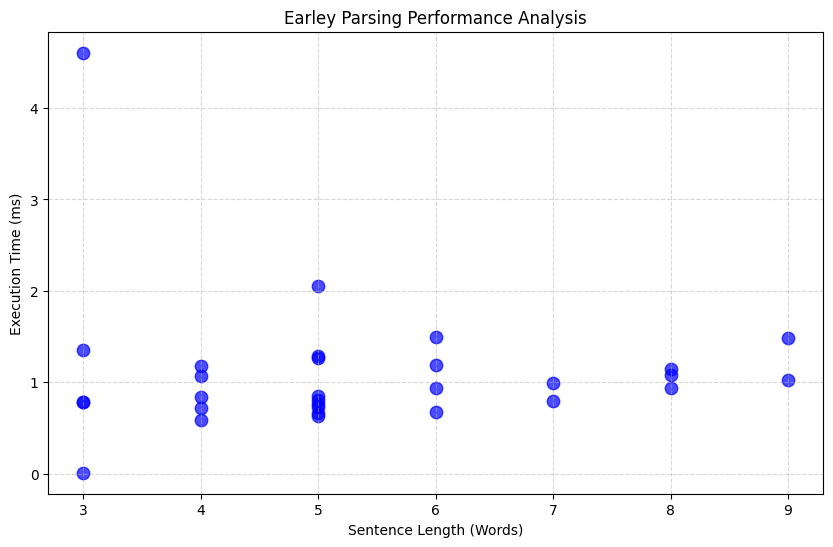

In [ ]:
# Plot Performance: Parsing Time vs Sentence Length
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df_results['Length'], df_results['Time (ms)'], color='blue', alpha=0.7, edgecolors='b', s=80)
plt.title('Earley Parsing Performance Analysis')
plt.xlabel('Sentence Length (Words)')
plt.ylabel('Execution Time (ms)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Run parser benchmarks and display detailed validation results
import pandas as pd

# Ensure queries and parsers are available
try:
    queries_list = queries
except NameError:
    # Fallback definition if execution state was cleared
    queries_list = [
        ("the student submits the fee", "Grammatical"),
        ("students check the timetables", "Grammatical"),
        ("I book the room", "Grammatical"),
        ("you apply for a hostel", "Grammatical"),
        ("the students submit the fees near the library", "Ambiguous PP"),
        ("book the room near the library for the seminar", "Ambiguous PP")
    ]

validation_results = []
for sentence_str, label in queries_list:
    tokens = sentence_str.split()
    # Test Earley Feature Parser
    try:
        earley_trees = list(earley_parser.parse(tokens))
        num_earley_parses = len(earley_trees)
    except Exception as e:
        num_earley_parses = 0

    # Test PCFG Viterbi Parser
    try:
        viterbi_trees = list(pcfg_viterbi_parser.parse(tokens))
        num_viterbi_parses = len(viterbi_trees)
    except Exception as e:
        num_viterbi_parses = 0

    validation_results.append({
        "Query": sentence_str,
        "Expected Category": label,
        "Earley Parsed": num_earley_parses > 0,
        "Earley Parse Count": num_earley_parses,
        "PCFG Parsed": num_viterbi_parses > 0
    })

df_validation = pd.DataFrame(validation_results)
display(df_validation.head(10))

,Query,Expected Category,Earley Parsed,Earley Parse Count,PCFG Parsed
0,the student submits the fee,Grammatical,False,0,False
1,students check the timetables,Grammatical,False,0,False
2,I book the room,Grammatical,False,0,False
3,you apply for a hostel,Grammatical,False,0,False
4,the students submit the fees near the library,Ambiguous PP,False,0,False
5,book the room near the library for the seminar,Ambiguous PP,False,0,False
